# El UDG Post-Pandemia: análisis de admisiones de la Red UdeG (2015-2025)

**Autor:** Oscar Alejandro González Carrillo · Licenciatura en Inteligencia Artificial y Ciencia de los Datos, CUGDL
**Materia:** Probabilidad y Estadística I

Este notebook toma la base relacional `udg_analisis` (MySQL), construye el conjunto de datos de admisión de los programas presenciales de la Red UdeG y produce las tablas y gráficas del reporte (`docs/reporte_udg_post_pandemia.pdf`).

**Pregunta central:** ¿cómo cambió la pandemia de COVID-19 la demanda, la selectividad y las preferencias académicas en la UdeG?

> Antes de ejecutar: carga `sql/01_schema.sql` y `sql/02_datos.sql` en MySQL y crea un archivo `.env` a partir de `.env.example`.

## 0 · Librerías

In [1]:
import os
import warnings
from pathlib import Path
from urllib.parse import quote_plus

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine

warnings.filterwarnings('ignore')

## 1 · Conexión a la base de datos

Se leen las credenciales desde variables de entorno (`.env`). **Nunca se escriben contraseñas en el notebook.**

In [2]:
# Las credenciales viven en un archivo .env (NO se sube a GitHub). Ver .env.example
load_dotenv(find_dotenv(usecwd=True))

DB_USER     = os.getenv("DB_USER", "root")
DB_PASSWORD = os.getenv("DB_PASSWORD", "")
DB_HOST     = os.getenv("DB_HOST", "localhost")
DB_NAME     = os.getenv("DB_NAME", "udg_analisis")

engine = create_engine(
    f"mysql+mysqlconnector://{DB_USER}:{quote_plus(DB_PASSWORD)}@{DB_HOST}/{DB_NAME}"
)

# Verificar conexión
with engine.connect() as conn:
    print(f"✅ Conexión exitosa a {DB_NAME}")

✅ Conexión exitosa a udg_analisis


## 2 · Colores y estilo UdeG

Paleta institucional de la UdeG, estilo global de Matplotlib y funciones auxiliares para guardar figuras.

In [3]:
UDG_ROJO     = '#C8102E'
UDG_AMARILLO = '#F5A800'
UDG_NEGRO    = '#1A1A1A'

plt.rcParams.update({
    'figure.facecolor' : 'white',
    'axes.facecolor'   : 'white',
    'axes.edgecolor'   : UDG_NEGRO,
    'axes.titlesize'   : 13,
    'axes.titleweight' : 'bold',
    'axes.titlecolor'  : UDG_NEGRO,
    'axes.labelsize'   : 11,
    'axes.labelcolor'  : UDG_NEGRO,
    'xtick.labelsize'  : 9,
    'ytick.labelsize'  : 9,
    'font.family'      : 'sans-serif',
    'grid.color'       : '#E0E0E0',
    'grid.linewidth'   : 0.8,
})

FIG_DIR = Path("../reports/figures")      # gráficas exportadas
OUT_DIR = Path("../data/processed")       # tablas exportadas
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{nombre}.png", dpi=150,
                bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close()
    print(f"✅ {nombre}.png guardado en reports/figures/")

def formato_miles(ax, eje='y'):
    fmt = mticker.FuncFormatter(lambda x, _: f'{int(x):,}')
    if eje == 'y': ax.yaxis.set_major_formatter(fmt)
    else:          ax.xaxis.set_major_formatter(fmt)

## 3 · Tabla con estilo UdeG

Función que da formato de tabla (colores UdeG) a los DataFrames en Jupyter.

In [4]:
def estilo_udg(df_tabla, titulo=""):
    return df_tabla.style\
        .set_caption(titulo)\
        .set_table_styles([
            {'selector': 'caption',
             'props': [('font-size','15px'),('font-weight','bold'),
                       ('color', UDG_ROJO),('padding','10px'),
                       ('caption-side','top')]},
            {'selector': 'thead th',
             'props': [('background-color', UDG_ROJO),('color','white'),
                       ('font-weight','bold'),('font-size','12px'),
                       ('padding','10px 14px'),('text-align','center'),
                       ('border',f'1px solid {UDG_NEGRO}')]},
            {'selector': 'tbody tr:nth-child(even) td',
             'props': [('background-color','#FFF8E7'),('color', UDG_NEGRO)]},
            {'selector': 'tbody tr:nth-child(odd) td',
             'props': [('background-color','white'),('color', UDG_NEGRO)]},
            {'selector': 'td',
             'props': [('padding','8px 14px'),('font-size','12px'),
                       ('border','1px solid #E0E0E0'),('text-align','center')]},
            {'selector': 'tbody tr:hover td',
             'props': [('background-color','#FFE599')]},
            {'selector': 'tbody tr:last-child td',
             'props': [('background-color', UDG_AMARILLO),
                       ('color', UDG_NEGRO),('font-weight','bold')]},
        ])\
        .format(thousands=',', precision=2)

## 4 · Consulta base principal

Consulta base: une `admision`, `ciclo_escolar`, `carrera` y `centro_universitario`. Se excluyen los programas virtuales (`es_virtual = 0`) porque su puntaje es fijo (60) y distorsiona la comparación de selectividad. Los `no_admitidos` negativos de 2020 (cupos ampliados en pandemia) se fijan en 0 y se etiqueta cada registro con su periodo.

In [5]:
df = pd.read_sql("""
    SELECT
        ce.año,
        ce.periodo,
        cu.nombre                                           AS centro,
        cu.tipo,
        ca.nombre                                           AS carrera,
        ca.es_virtual,
        a.aspirantes,
        a.cupo,
        a.admitidos,
        a.puntaje_minimo,
        ROUND(a.admitidos / a.aspirantes * 100, 2)         AS tasa_admision,
        a.aspirantes - a.admitidos                         AS no_admitidos
    FROM admision a
    JOIN ciclo_escolar ce        ON a.id_ciclo   = ce.id_ciclo
    JOIN carrera ca              ON a.id_carrera = ca.id_carrera
    JOIN centro_universitario cu ON ca.id_centro = cu.id_centro
    WHERE ca.es_virtual = 0
    ORDER BY ce.año, ce.periodo, cu.nombre
""", engine)

# Corregir no_admitidos negativos (pandemia — cupos ampliados)
df['no_admitidos'] = df['no_admitidos'].clip(lower=0)

# Etiqueta de período
df['periodo_pandemia'] = pd.cut(
    df['año'],
    bins=[2014, 2019, 2021, 2025],
    labels=['Pre-pandemia (2015-2019)',
            'Pandemia (2020-2021)',
            'Post-pandemia (2022-2025)']
)

print(f"✅ DataFrame cargado: {len(df):,} filas × {df.shape[1]} columnas")

✅ DataFrame cargado: 4,810 filas × 13 columnas


## 5 · Exploración inicial

Totales globales, comparación metropolitano vs. regional y resumen por año.

In [6]:
totales = pd.read_sql("""
    SELECT
        COUNT(DISTINCT cu.id_centro)                       AS total_centros,
        COUNT(DISTINCT ca.id_carrera)                      AS total_carreras,
        COUNT(DISTINCT ce.año)                             AS años_cubiertos,
        COUNT(*)                                           AS total_registros,
        SUM(a.aspirantes)                                  AS total_aspirantes,
        SUM(a.admitidos)                                   AS total_admitidos,
        SUM(a.cupo)                                        AS total_cupo_ofertado,
        ROUND(SUM(a.admitidos)/SUM(a.aspirantes)*100, 2)   AS tasa_admision_global
    FROM admision a
    JOIN carrera ca              ON a.id_carrera = ca.id_carrera
    JOIN centro_universitario cu ON ca.id_centro = cu.id_centro
    JOIN ciclo_escolar ce        ON a.id_ciclo   = ce.id_ciclo
    WHERE ca.es_virtual = 0
""", engine)

tipo = pd.read_sql("""
    SELECT
        cu.tipo,
        COUNT(DISTINCT cu.id_centro)                       AS centros,
        COUNT(DISTINCT ca.id_carrera)                      AS carreras,
        SUM(a.aspirantes)                                  AS aspirantes,
        SUM(a.admitidos)                                   AS admitidos,
        ROUND(SUM(a.admitidos)/SUM(a.aspirantes)*100, 2)   AS tasa_admision
    FROM admision a
    JOIN carrera ca              ON a.id_carrera = ca.id_carrera
    JOIN centro_universitario cu ON ca.id_centro = cu.id_centro
    WHERE ca.es_virtual = 0
    GROUP BY cu.tipo
""", engine)

por_año = pd.read_sql("""
    SELECT
        ce.año,
        SUM(a.aspirantes)                                  AS aspirantes,
        SUM(a.admitidos)                                   AS admitidos,
        SUM(a.cupo)                                        AS cupo,
        ROUND(SUM(a.admitidos)/SUM(a.aspirantes)*100, 2)   AS tasa_admision
    FROM admision a
    JOIN carrera ca        ON a.id_carrera = ca.id_carrera
    JOIN ciclo_escolar ce  ON a.id_ciclo   = ce.id_ciclo
    WHERE ca.es_virtual = 0
    GROUP BY ce.año
    ORDER BY ce.año
""", engine)

### Variables cualitativas

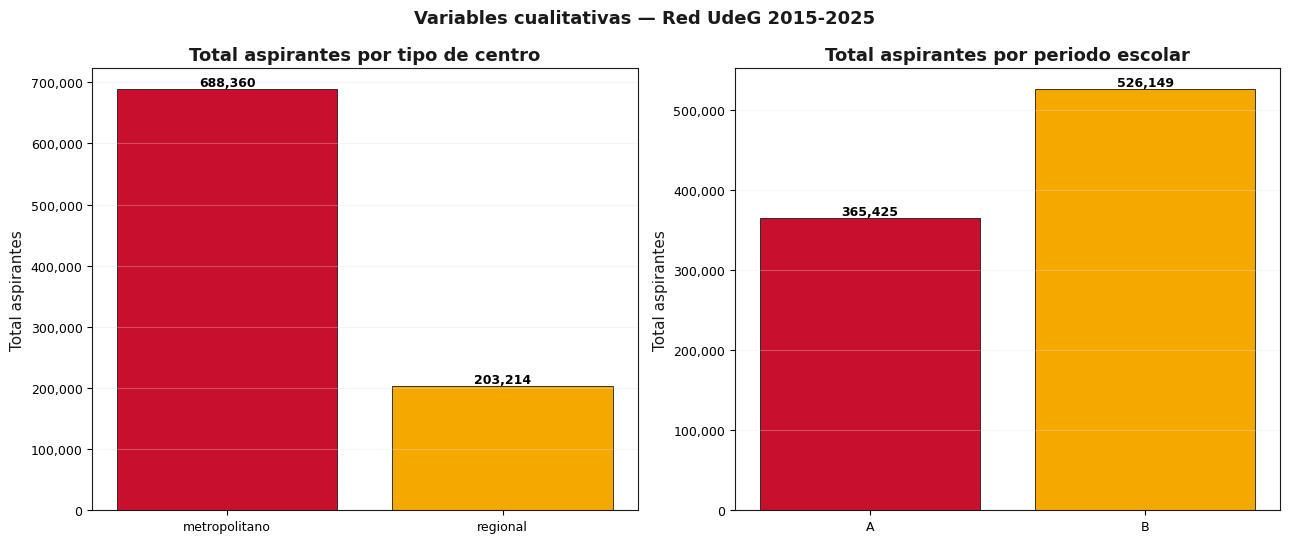

✅ g0_variables_cualitativas.png guardado en reports/figures/


In [7]:
# Variables cualitativas: aspirantes por tipo de centro y por periodo escolar
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle('Variables cualitativas — Red UdeG 2015-2025', fontsize=13, fontweight='bold', color=UDG_NEGRO)

for ax, col, titulo in [(axes[0], 'tipo', 'Total aspirantes por tipo de centro'),
                        (axes[1], 'periodo', 'Total aspirantes por periodo escolar')]:
    s = df.groupby(col)['aspirantes'].sum()
    bars = ax.bar(s.index, s.values, color=[UDG_ROJO, UDG_AMARILLO], edgecolor=UDG_NEGRO, linewidth=0.6)
    for b, v in zip(bars, s.values):
        ax.text(b.get_x() + b.get_width()/2, v, f'{v:,}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.set_title(titulo)
    ax.set_ylabel('Total aspirantes')
    ax.grid(axis='y', alpha=0.3)
    formato_miles(ax)
guardar("g0_variables_cualitativas")

## 6 · Estadística descriptiva

Estadística descriptiva (media, mediana, desviación estándar, rango y coeficiente de variación) y tablas de frecuencia de las variables cualitativas.

In [8]:
vars_desc = ['aspirantes', 'admitidos', 'tasa_admision', 'puntaje_minimo']

desc = df[vars_desc].describe().T
desc['rango'] = desc['max'] - desc['min']
desc['cv_%']  = round((desc['std'] / desc['mean']) * 100, 2)
desc = desc[['mean','50%','std','rango','cv_%','min','max']].round(2)
desc.columns = ['Media','Mediana','Desv. Estándar','Rango','CV (%)','Mínimo','Máximo']

# Frecuencias — variables cualitativas
freq_tipo = df['tipo'].value_counts().reset_index()
freq_tipo.columns = ['tipo', 'Frecuencia']
freq_tipo['Proporción (%)'] = round(
    freq_tipo['Frecuencia'] / freq_tipo['Frecuencia'].sum() * 100, 2)

freq_periodo = df['periodo'].value_counts().reset_index()
freq_periodo.columns = ['periodo', 'Frecuencia']
freq_periodo['Proporción (%)'] = round(
    freq_periodo['Frecuencia'] / freq_periodo['Frecuencia'].sum() * 100, 2)

freq_centro = df['centro'].value_counts().reset_index()
freq_centro.columns = ['centro', 'Frecuencia']
freq_centro['Proporción (%)'] = round(
    freq_centro['Frecuencia'] / freq_centro['Frecuencia'].sum() * 100, 2)

### Validación contra el reporte

Comprueba que la base reproduce las cifras publicadas en el reporte.

In [9]:
# Validación: las cifras del análisis deben coincidir con las del reporte
t = totales.iloc[0]
checks = [
    ("Aspirantes totales 2015-2025",  int(t['total_aspirantes']), 891_574),
    ("Admitidos totales 2015-2025",   int(t['total_admitidos']),  356_073),
    ("Tasa de admisión global (%)",   float(t['tasa_admision_global']), 39.94),
    ("Aspirantes 2020",               int(por_año.loc[por_año['año'] == 2020, 'aspirantes'].iloc[0]), 91_022),
]
for nombre, obtenido, esperado in checks:
    estado = "✅" if obtenido == esperado else "❌"
    print(f"{estado} {nombre}: {obtenido:,} (reporte: {esperado:,})")

✅ Aspirantes totales 2015-2025: 891,574 (reporte: 891,574)
✅ Admitidos totales 2015-2025: 356,073 (reporte: 356,073)
✅ Tasa de admisión global (%): 39.94 (reporte: 39.94)
✅ Aspirantes 2020: 91,022 (reporte: 91,022)


### Comparativo por periodo

Pre-pandemia (2015-2019), pandemia (2020-2021) y post-pandemia (2022-2025). Nota: el periodo post-pandemia tiene 4 años y el pre-pandemia 5, por lo que los totales absolutos no son directamente comparables; las tasas sí.

In [10]:
# Comparativo por periodo: pre-pandemia vs pandemia vs post-pandemia
por_periodo = (
    df.groupby('periodo_pandemia', observed=True)
      .agg(total_aspirantes=('aspirantes', 'sum'),
           total_admitidos=('admitidos', 'sum'),
           total_cupo=('cupo', 'sum'),
           puntaje_promedio=('puntaje_minimo', 'mean'))
      .reset_index()
)
por_periodo['tasa_admision'] = (por_periodo['total_admitidos'] / por_periodo['total_aspirantes'] * 100).round(2)
por_periodo['puntaje_promedio'] = por_periodo['puntaje_promedio'].round(2)
estilo_udg(por_periodo, "Indicadores de admisión por periodo — Red UdeG")

,periodo_pandemia,total_aspirantes,total_admitidos,total_cupo,puntaje_promedio,tasa_admision
0,Pre-pandemia (2015-2019),"394,740","151,991","161,720",123.50,38.50
1,Pandemia (2020-2021),"176,414","67,110","67,940",101.88,38.04
2,Post-pandemia (2022-2025),"320,420","136,972","149,481",113.79,42.75


## 7 · Gráfica 1 · Top 10 carreras por demanda

**Top 10 de carreras por demanda acumulada.** Medicina duplica a la segunda carrera más solicitada.

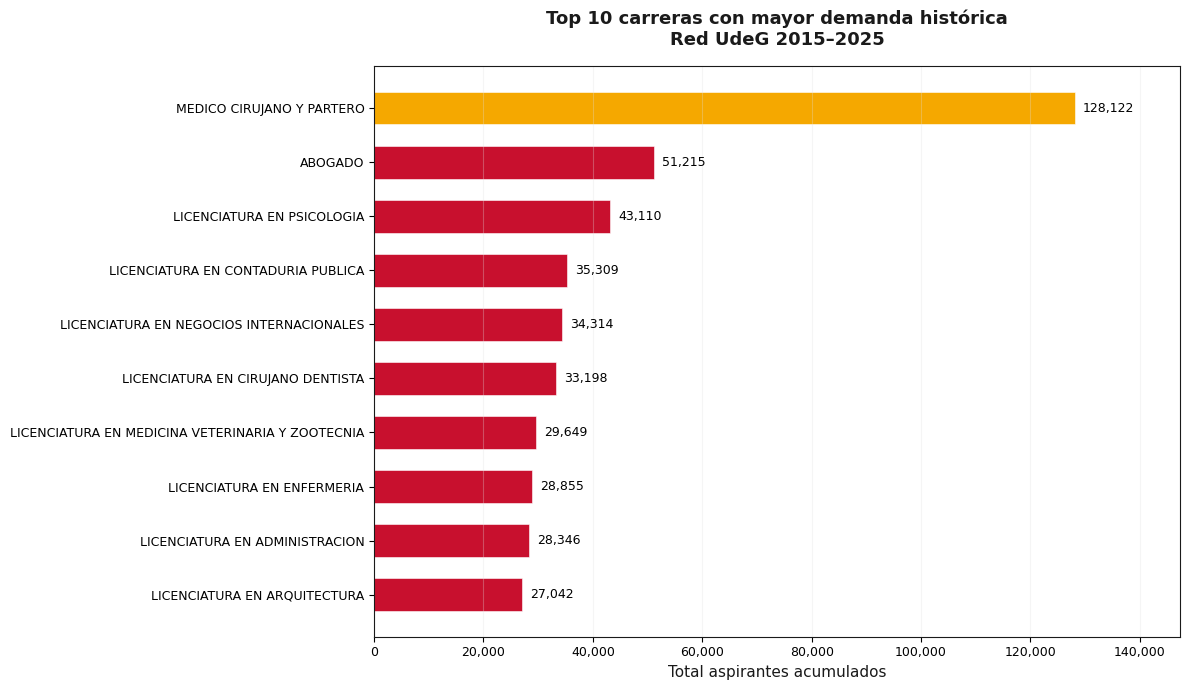

✅ g1_top10_carreras.png guardado en reports/figures/


In [11]:
top10 = df.groupby('carrera')['aspirantes'].sum()\
          .sort_values(ascending=True).tail(10).reset_index()

fig, ax = plt.subplots(figsize=(12, 7))
colores = [UDG_AMARILLO if i == 9 else UDG_ROJO for i in range(10)]
bars = ax.barh(top10['carrera'], top10['aspirantes'],
               color=colores, edgecolor='white', linewidth=0.4, height=0.6)
for bar, val in zip(bars, top10['aspirantes']):
    ax.text(val + 1500, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=9)
ax.set_title('Top 10 carreras con mayor demanda histórica\nRed UdeG 2015–2025',
             fontsize=13, fontweight='bold', color=UDG_NEGRO, pad=15)
ax.set_xlabel('Total aspirantes acumulados')
ax.grid(axis='x', alpha=0.3)
ax.set_xlim(0, top10['aspirantes'].max() * 1.15)
formato_miles(ax, 'x')
guardar("g1_top10_carreras")

## 8 · Gráfica 2 · Aspirantes por campus

Aspirantes acumulados por campus. El CUCS concentra la mayor demanda de la red.

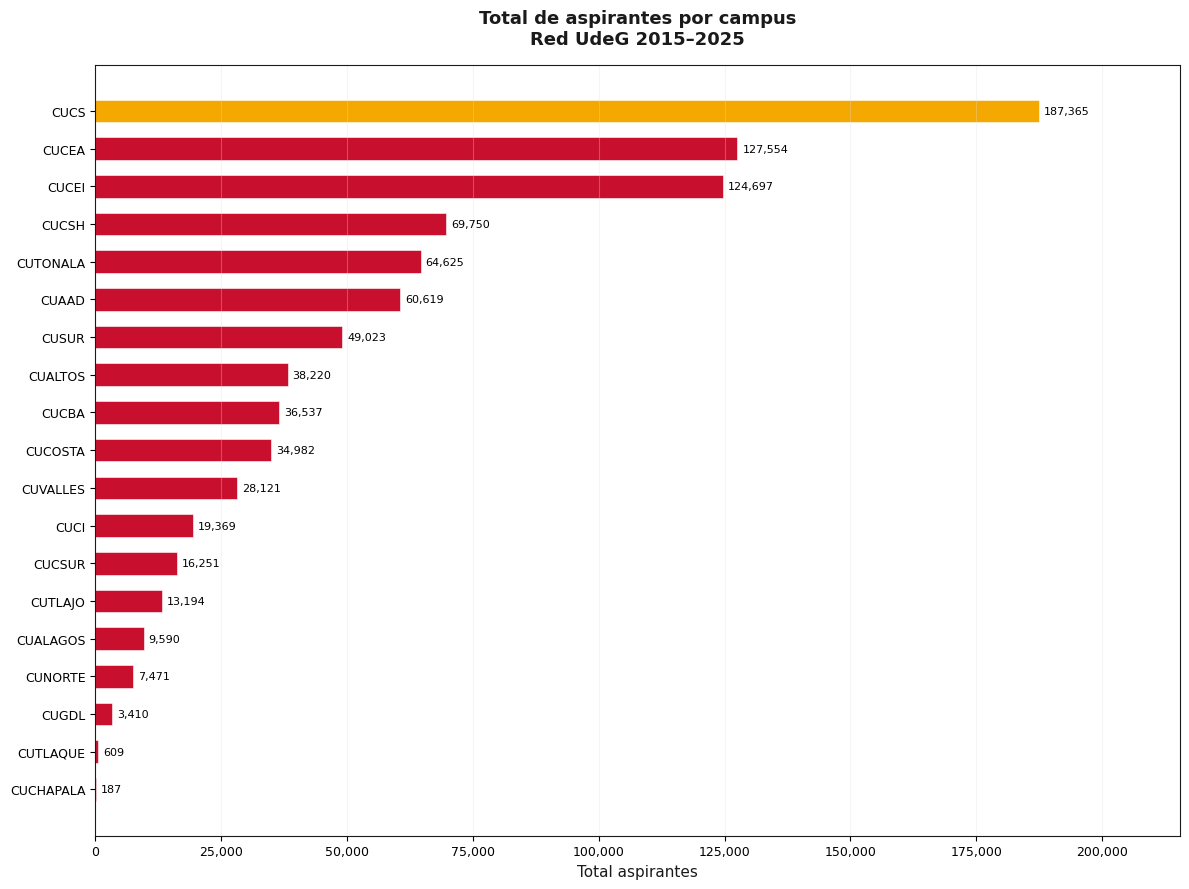

✅ g2_aspirantes_por_campus.png guardado en reports/figures/


In [12]:
campus_asp = df.groupby('centro')['aspirantes'].sum()\
               .sort_values(ascending=True).reset_index()

fig, ax = plt.subplots(figsize=(12, 9))
colores = [UDG_AMARILLO if i == len(campus_asp)-1 else UDG_ROJO
           for i in range(len(campus_asp))]
bars = ax.barh(campus_asp['centro'], campus_asp['aspirantes'],
               color=colores, edgecolor='white', linewidth=0.4, height=0.6)
for bar, val in zip(bars, campus_asp['aspirantes']):
    ax.text(val + 1000, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=8)
ax.set_title('Total de aspirantes por campus\nRed UdeG 2015–2025',
             fontsize=13, fontweight='bold', color=UDG_NEGRO, pad=15)
ax.set_xlabel('Total aspirantes')
ax.grid(axis='x', alpha=0.3)
ax.set_xlim(0, campus_asp['aspirantes'].max() * 1.15)
formato_miles(ax, 'x')
guardar("g2_aspirantes_por_campus")

## 9 · Gráfica 3 · Admitidos por campus

Admitidos acumulados por campus.

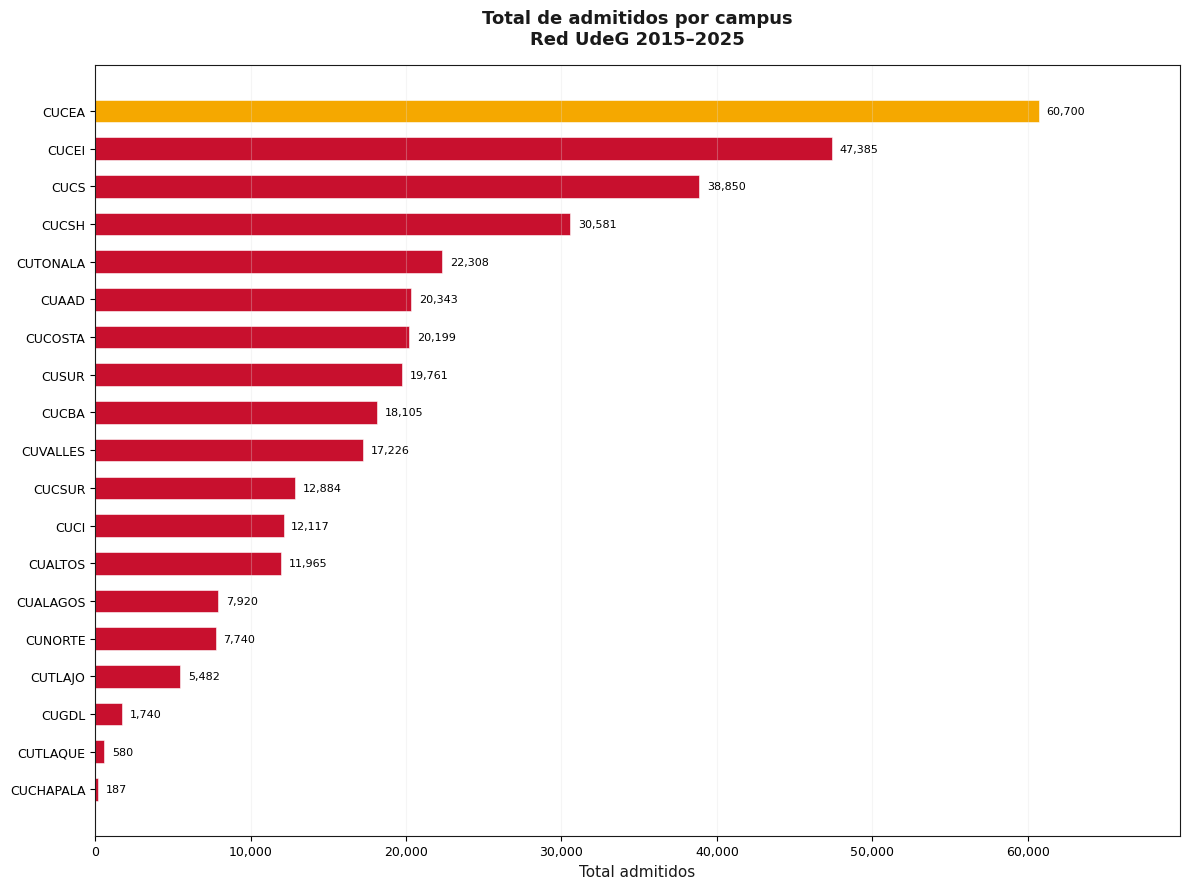

✅ g3_admitidos_por_campus.png guardado en reports/figures/


In [13]:
campus_adm = df.groupby('centro')['admitidos'].sum()\
               .sort_values(ascending=True).reset_index()

fig, ax = plt.subplots(figsize=(12, 9))
colores = [UDG_AMARILLO if i == len(campus_adm)-1 else UDG_ROJO
           for i in range(len(campus_adm))]
bars = ax.barh(campus_adm['centro'], campus_adm['admitidos'],
               color=colores, edgecolor='white', linewidth=0.4, height=0.6)
for bar, val in zip(bars, campus_adm['admitidos']):
    ax.text(val + 500, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=8)
ax.set_title('Total de admitidos por campus\nRed UdeG 2015–2025',
             fontsize=13, fontweight='bold', color=UDG_NEGRO, pad=15)
ax.set_xlabel('Total admitidos')
ax.grid(axis='x', alpha=0.3)
ax.set_xlim(0, campus_adm['admitidos'].max() * 1.15)
formato_miles(ax, 'x')
guardar("g3_admitidos_por_campus")

## 10 · Gráfica 4 · Tasa de admisión por campus

Tasa de admisión por campus frente al promedio de la red.

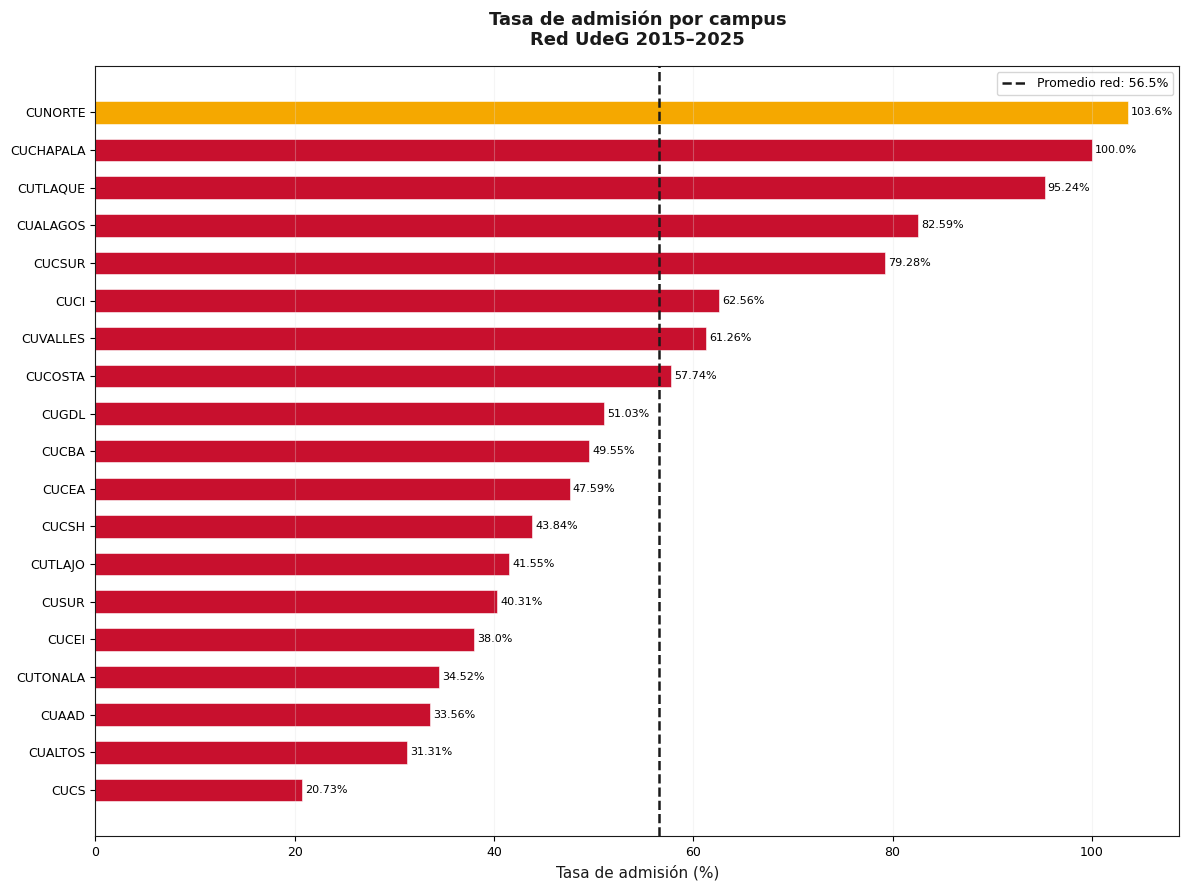

✅ g4_tasa_admision_campus.png guardado en reports/figures/


In [14]:
campus_tasa = df.groupby('centro').apply(
    lambda x: round(x['admitidos'].sum() / x['aspirantes'].sum() * 100, 2)
).sort_values(ascending=True).reset_index()
campus_tasa.columns = ['centro', 'tasa']

fig, ax = plt.subplots(figsize=(12, 9))
colores = [UDG_AMARILLO if i == len(campus_tasa)-1 else UDG_ROJO
           for i in range(len(campus_tasa))]
bars = ax.barh(campus_tasa['centro'], campus_tasa['tasa'],
               color=colores, edgecolor='white', linewidth=0.4, height=0.6)
ax.axvline(campus_tasa['tasa'].mean(), color=UDG_NEGRO,
           linestyle='--', linewidth=1.8,
           label=f"Promedio red: {campus_tasa['tasa'].mean():.1f}%")
for bar, val in zip(bars, campus_tasa['tasa']):
    ax.text(val + 0.3, bar.get_y() + bar.get_height()/2,
            f'{val}%', va='center', fontsize=8)
ax.set_title('Tasa de admisión por campus\nRed UdeG 2015–2025',
             fontsize=13, fontweight='bold', color=UDG_NEGRO, pad=15)
ax.set_xlabel('Tasa de admisión (%)')
ax.legend(fontsize=9)
ax.grid(axis='x', alpha=0.3)
guardar("g4_tasa_admision_campus")

## 11 · Gráfica 5 · Evolución temporal

Evolución de aspirantes y admitidos con el periodo pandémico sombreado. 2020 es el año con más aspirantes de toda la serie.

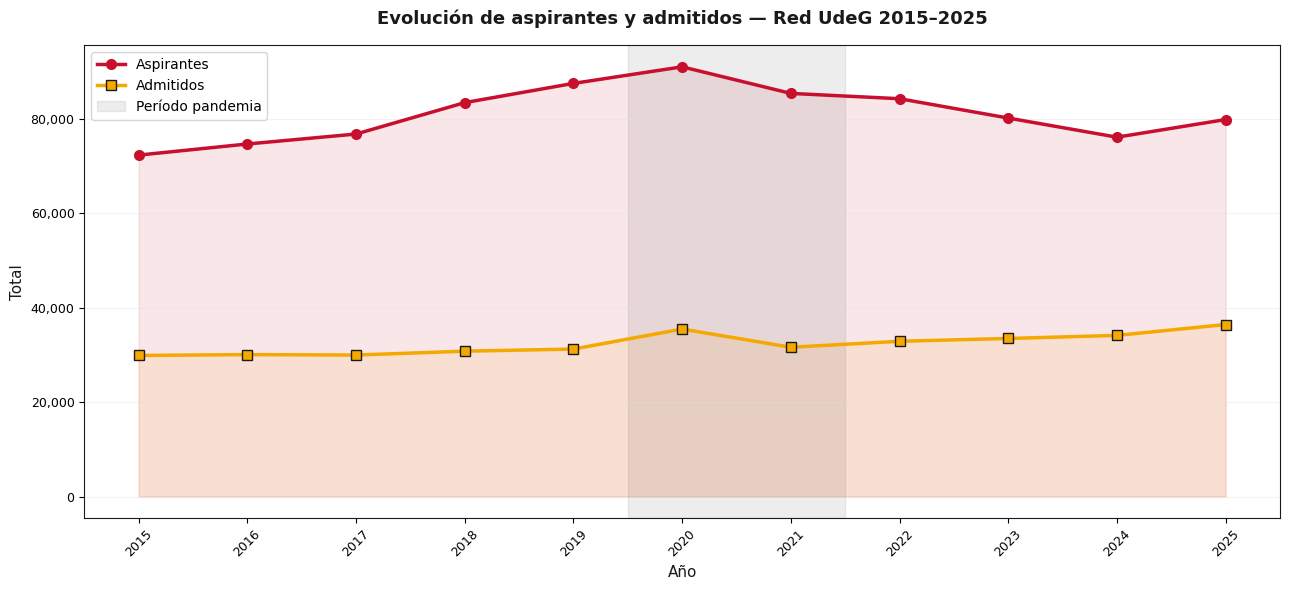

✅ g5_evolucion_temporal.png guardado en reports/figures/


In [15]:
evol = df.groupby('año')[['aspirantes','admitidos']].sum().reset_index()

fig, ax = plt.subplots(figsize=(13, 6))
ax.fill_between(evol['año'], evol['aspirantes'], alpha=0.1, color=UDG_ROJO)
ax.fill_between(evol['año'], evol['admitidos'],  alpha=0.1, color=UDG_AMARILLO)
ax.plot(evol['año'], evol['aspirantes'], color=UDG_ROJO, linewidth=2.5,
        marker='o', markersize=7, label='Aspirantes')
ax.plot(evol['año'], evol['admitidos'],  color=UDG_AMARILLO, linewidth=2.5,
        marker='s', markersize=7, markeredgecolor=UDG_NEGRO, label='Admitidos')
ax.axvspan(2019.5, 2021.5, alpha=0.08, color=UDG_NEGRO, label='Período pandemia')
ax.set_title('Evolución de aspirantes y admitidos — Red UdeG 2015–2025',
             fontsize=13, fontweight='bold', color=UDG_NEGRO, pad=15)
ax.set_xlabel('Año')
ax.set_ylabel('Total')
ax.set_xticks(evol['año'])
ax.tick_params(axis='x', rotation=45)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.4)
formato_miles(ax)
guardar("g5_evolucion_temporal")

## 12 · Gráfica 6 · Distribución de la tasa de admisión

Distribución de la tasa de admisión por carrera y ciclo. La media (71.7%) queda por debajo de la mediana (76.9%): la mayoría de los programas admite a casi todos sus aspirantes, y la demanda se concentra en pocas carreras. La cola derecha (>100%) corresponde a los ajustes de emergencia de 2020.

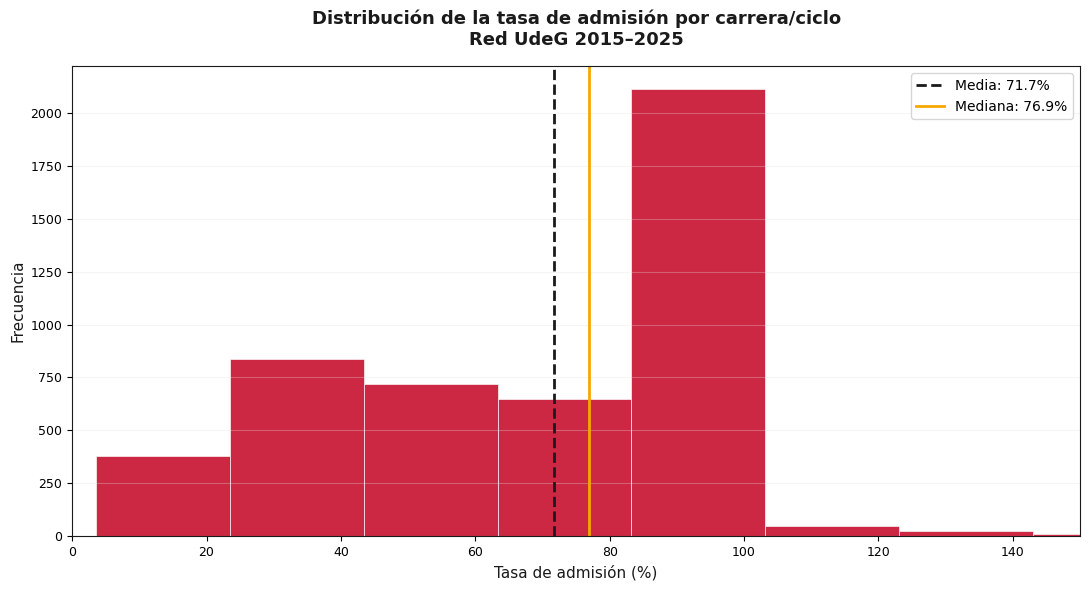

✅ g6_histograma_tasa_admision.png guardado en reports/figures/


In [16]:
serie = df['tasa_admision'].dropna()

fig, ax = plt.subplots(figsize=(11, 6))
ax.hist(serie, bins=50, color=UDG_ROJO, edgecolor='white',
        linewidth=0.5, alpha=0.9)
ax.axvline(serie.mean(),   color=UDG_NEGRO,    linestyle='--',
           linewidth=2, label=f'Media: {serie.mean():.1f}%')
ax.axvline(serie.median(), color=UDG_AMARILLO, linestyle='-',
           linewidth=2, label=f'Mediana: {serie.median():.1f}%')
ax.set_title('Distribución de la tasa de admisión por carrera/ciclo\nRed UdeG 2015–2025',
             fontsize=13, fontweight='bold', color=UDG_NEGRO, pad=15)
ax.set_xlim(0, 150)   # vista recortada: los valores extremos (hasta 1,000%) son datos de 2020
ax.set_xlabel('Tasa de admisión (%)')
ax.set_ylabel('Frecuencia')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
guardar("g6_histograma_tasa_admision")

## 13 · Gráfica 7 · Puntaje mínimo por periodo

Distribución del puntaje mínimo por periodo: cae en pandemia y se recupera solo parcialmente después.

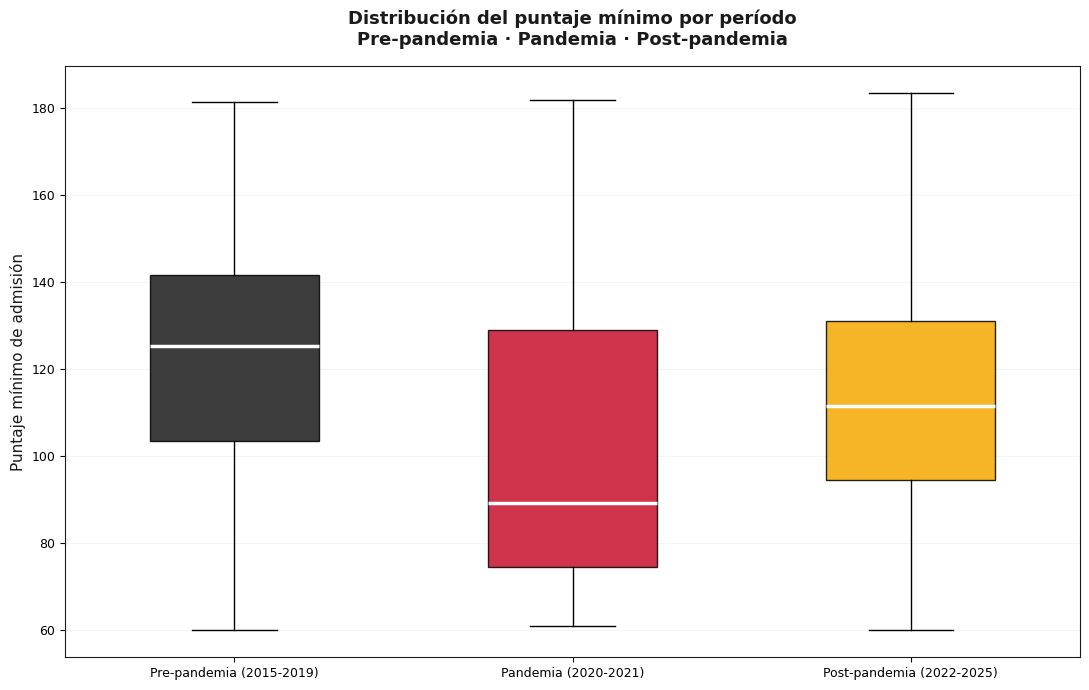

✅ g7_boxplot_puntaje_periodo.png guardado en reports/figures/


In [17]:
fig, ax = plt.subplots(figsize=(11, 7))
colores_box = [UDG_NEGRO, UDG_ROJO, UDG_AMARILLO]
categorias  = df['periodo_pandemia'].cat.categories.tolist()
grupos      = [df[df['periodo_pandemia'] == p]['puntaje_minimo'].dropna()
               for p in categorias]

bp = ax.boxplot(grupos, labels=categorias, patch_artist=True,
                medianprops=dict(color='white', linewidth=2.5),
                flierprops=dict(marker='o', markersize=3,
                                alpha=0.3, color=UDG_NEGRO),
                widths=0.5)
for patch, color in zip(bp['boxes'], colores_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)

ax.set_title('Distribución del puntaje mínimo por período\nPre-pandemia · Pandemia · Post-pandemia',
             fontsize=13, fontweight='bold', color=UDG_NEGRO, pad=15)
ax.set_ylabel('Puntaje mínimo de admisión')
ax.grid(axis='y', alpha=0.3)
guardar("g7_boxplot_puntaje_periodo")

## 14 · Gráfica 8 · Carreras tecnológicas y de salud

Carreras tecnológicas y de salud seleccionadas.

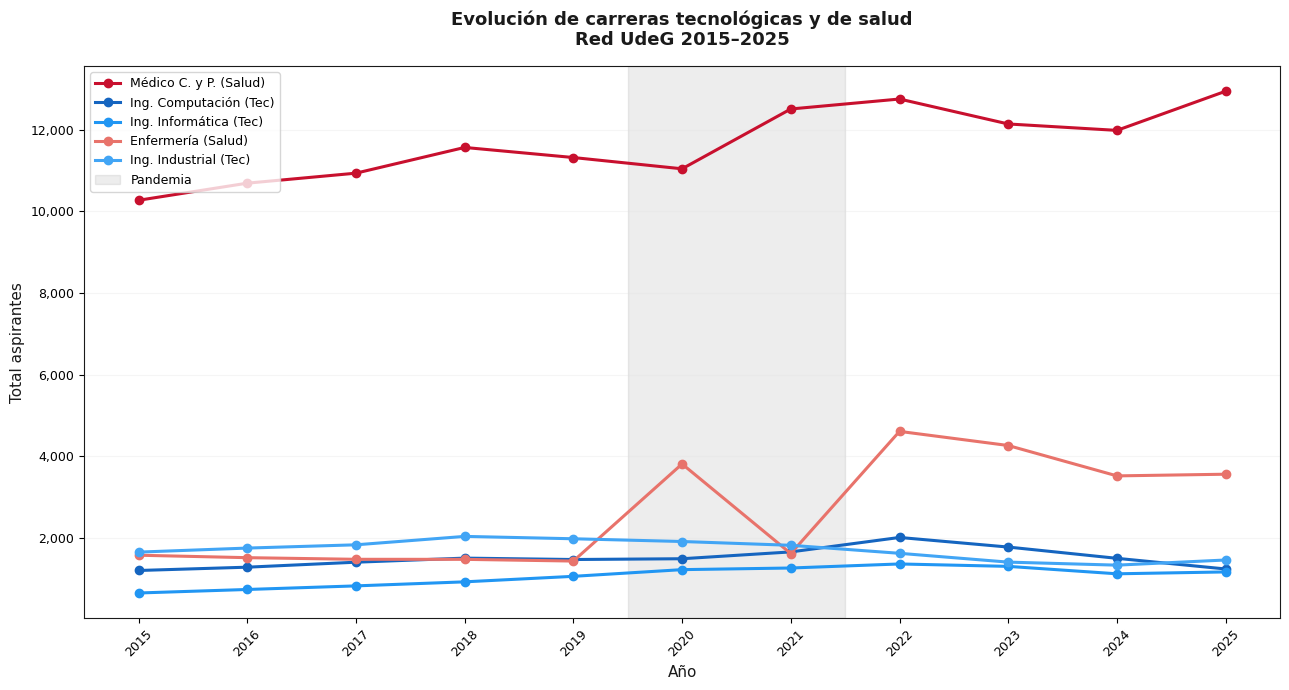

✅ g8_boom_tec_salud.png guardado en reports/figures/


In [18]:
carreras_sel = {
    'MEDICO CIRUJANO Y PARTERO'  : ('Médico C. y P. (Salud)',    UDG_ROJO),
    'INGENIERIA EN COMPUTACION'  : ('Ing. Computación (Tec)',     '#1565C0'),
    'INGENIERIA INFORMATICA'     : ('Ing. Informática (Tec)',     '#2196F3'),
    'LICENCIATURA EN ENFERMERIA' : ('Enfermería (Salud)',         '#E8736B'),
    'INGENIERIA INDUSTRIAL'      : ('Ing. Industrial (Tec)',      '#42A5F5'),
}

boom = df[df['carrera'].isin(carreras_sel.keys())]\
       .groupby(['año','carrera'])['aspirantes'].sum().reset_index()

fig, ax = plt.subplots(figsize=(13, 7))
for carrera, (etiqueta, color) in carreras_sel.items():
    data = boom[boom['carrera'] == carrera]
    if not data.empty:
        ax.plot(data['año'], data['aspirantes'], marker='o',
                linewidth=2.2, markersize=6, color=color, label=etiqueta)

ax.axvspan(2019.5, 2021.5, alpha=0.08, color=UDG_NEGRO, label='Pandemia')
ax.set_title('Evolución de carreras tecnológicas y de salud\nRed UdeG 2015–2025',
             fontsize=13, fontweight='bold', color=UDG_NEGRO, pad=15)
ax.set_xlabel('Año')
ax.set_ylabel('Total aspirantes')
ax.set_xticks(sorted(boom['año'].unique()))
ax.tick_params(axis='x', rotation=45)
ax.legend(fontsize=9, loc='upper left')
ax.grid(axis='y', alpha=0.3)
formato_miles(ax)
guardar("g8_boom_tec_salud")

## 15 · Gráfica 9 · Top 10 con mayor caída (2019 vs 2025)

**Carreras con mayor caída de demanda** entre 2019 (pre-pandemia) y 2025. Predominan ciencias sociales y humanidades.

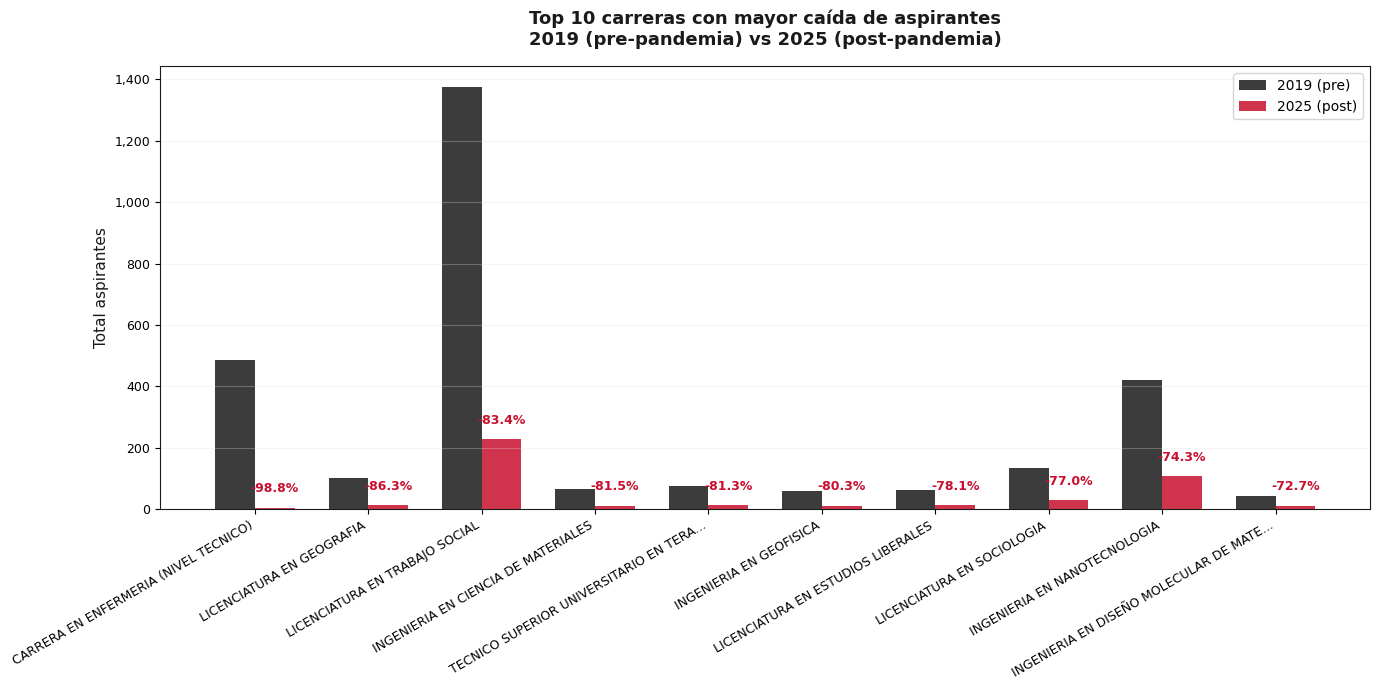

✅ g9_top10_perdedores_pandemia.png guardado en reports/figures/


In [19]:
asp_2019 = df[df['año'] == 2019].groupby('carrera')['aspirantes'].sum()
asp_2025 = df[df['año'] == 2025].groupby('carrera')['aspirantes'].sum()

perdedores = pd.DataFrame({'2019': asp_2019, '2025': asp_2025}).dropna()
perdedores['cambio_%'] = ((perdedores['2025'] - perdedores['2019'])
                           / perdedores['2019'] * 100).round(1)
top10_perd = perdedores.sort_values('cambio_%').head(10).reset_index()

fig, ax = plt.subplots(figsize=(14, 7))
x = range(len(top10_perd))
w = 0.35
ax.bar([i - w/2 for i in x], top10_perd['2019'], width=w,
       color=UDG_NEGRO, label='2019 (pre)', alpha=0.85)
ax.bar([i + w/2 for i in x], top10_perd['2025'], width=w,
       color=UDG_ROJO,  label='2025 (post)', alpha=0.85)
for i, (_, row) in enumerate(top10_perd.iterrows()):
    ax.text(i + w/2, row['2025'] + 50, f"{row['cambio_%']}%",
            ha='center', fontsize=9, color=UDG_ROJO, fontweight='bold')
ax.set_xticks(list(x))
ax.set_xticklabels(
    [c[:38]+'...' if len(c) > 38 else c for c in top10_perd['carrera']],
    rotation=30, ha='right', fontsize=9)
ax.set_title('Top 10 carreras con mayor caída de aspirantes\n2019 (pre-pandemia) vs 2025 (post-pandemia)',
             fontsize=13, fontweight='bold', color=UDG_NEGRO, pad=15)
ax.set_ylabel('Total aspirantes')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
formato_miles(ax)
guardar("g9_top10_perdedores_pandemia")

## 16 · Gráfica 10 · Campus 2015 vs 2025

Aspirantes por campus: 2015 vs. 2025.

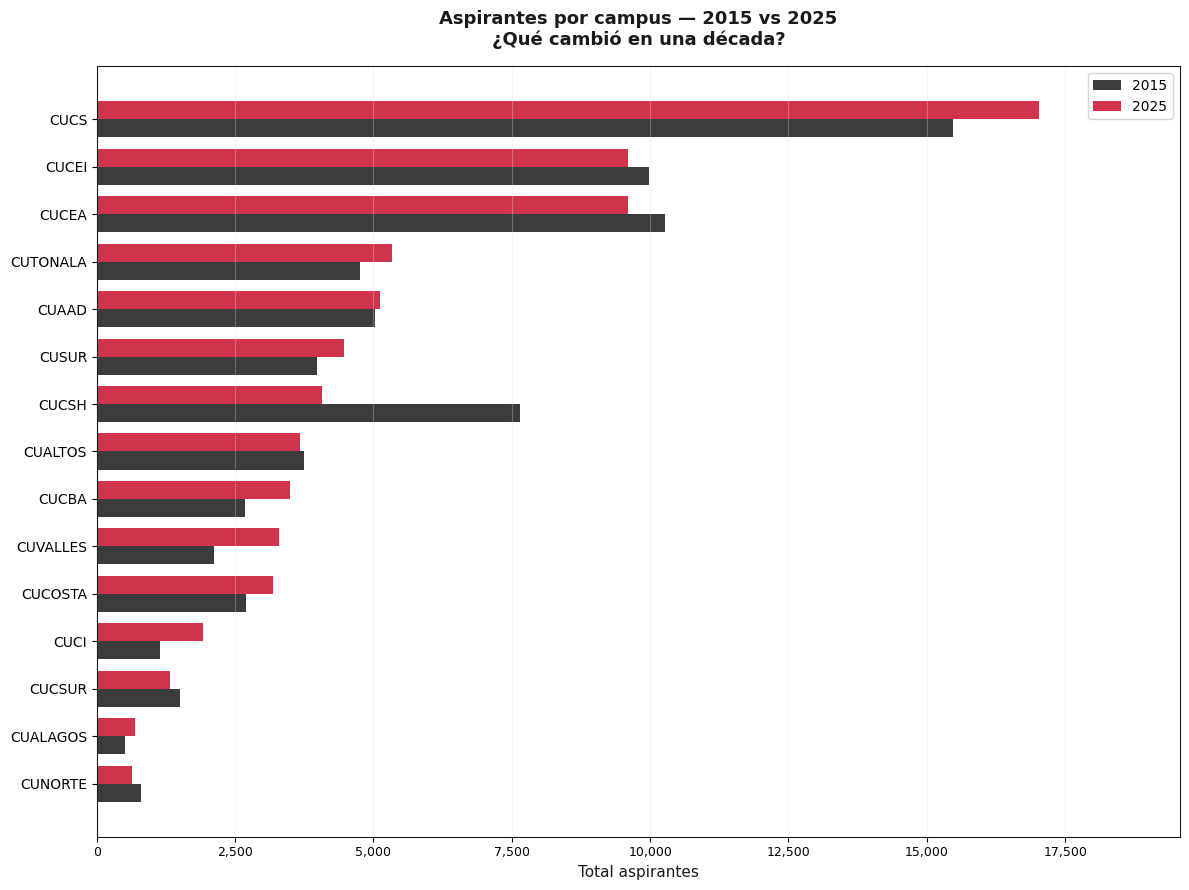

✅ g10_campus_2015_vs_2025.png guardado en reports/figures/


In [20]:
asp_15 = df[df['año'] == 2015].groupby('centro')['aspirantes'].sum()
asp_25 = df[df['año'] == 2025].groupby('centro')['aspirantes'].sum()
comp   = pd.DataFrame({'2015': asp_15, '2025': asp_25}).dropna()\
           .sort_values('2025', ascending=True).reset_index()

fig, ax = plt.subplots(figsize=(12, 9))
x = range(len(comp))
w = 0.38
ax.barh([i - w/2 for i in x], comp['2015'], height=w,
        color=UDG_NEGRO, label='2015', alpha=0.85)
ax.barh([i + w/2 for i in x], comp['2025'], height=w,
        color=UDG_ROJO,  label='2025', alpha=0.85)
ax.set_yticks(list(x))
ax.set_yticklabels(comp['centro'], fontsize=10)
ax.set_title('Aspirantes por campus — 2015 vs 2025\n¿Qué cambió en una década?',
             fontsize=13, fontweight='bold', color=UDG_NEGRO, pad=15)
ax.set_xlabel('Total aspirantes')
ax.legend(fontsize=10)
ax.grid(axis='x', alpha=0.3)
ax.set_xlim(0, comp[['2015','2025']].max().max() * 1.15)
formato_miles(ax, 'x')
guardar("g10_campus_2015_vs_2025")

## 17 · Gráfica 11 · Tasa de admisión histórica

Tasa de admisión global por año.

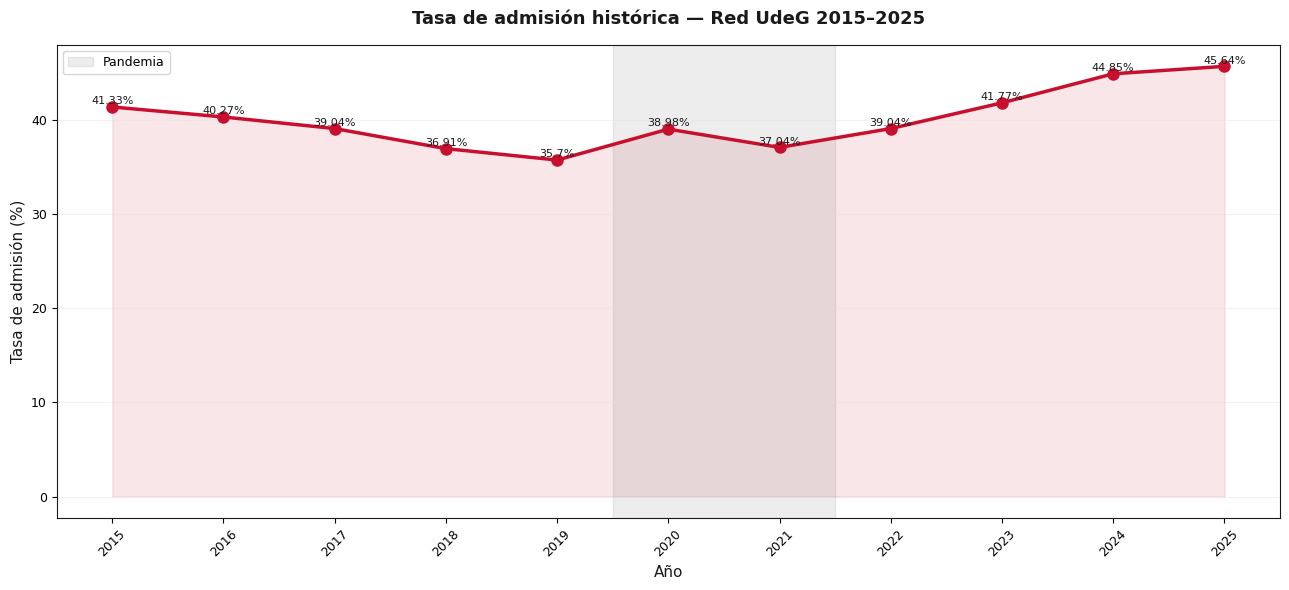

✅ g11_tasa_admision_historica.png guardado en reports/figures/


In [21]:
tasa_año = df.groupby('año').apply(
    lambda x: round(x['admitidos'].sum() / x['aspirantes'].sum() * 100, 2)
).reset_index()
tasa_año.columns = ['año', 'tasa']

fig, ax = plt.subplots(figsize=(13, 6))
ax.fill_between(tasa_año['año'], tasa_año['tasa'],
                alpha=0.1, color=UDG_ROJO)
ax.plot(tasa_año['año'], tasa_año['tasa'], color=UDG_ROJO,
        linewidth=2.5, marker='o', markersize=8)
for _, row in tasa_año.iterrows():
    ax.text(row['año'], row['tasa'] + 0.3,
            f"{row['tasa']}%", ha='center', fontsize=8, color=UDG_NEGRO)
ax.axvspan(2019.5, 2021.5, alpha=0.08, color=UDG_NEGRO, label='Pandemia')
ax.set_title('Tasa de admisión histórica — Red UdeG 2015–2025',
             fontsize=13, fontweight='bold', color=UDG_NEGRO, pad=15)
ax.set_xlabel('Año')
ax.set_ylabel('Tasa de admisión (%)')
ax.set_xticks(tasa_año['año'])
ax.tick_params(axis='x', rotation=45)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.4)
guardar("g11_tasa_admision_historica")

## 18 · Exportar tablas a Excel

Exporta las tablas del análisis y las tablas base a `data/processed/udg_analisis_datos.xlsx`.

In [22]:
ruta_excel = OUT_DIR / "udg_analisis_datos.xlsx"
with pd.ExcelWriter(ruta_excel, engine="openpyxl") as writer:
    # Tablas del análisis
    desc.reset_index().rename(columns={'index':'Variable'})\
        .to_excel(writer, sheet_name="Estadistica descriptiva", index=False)
    por_año.to_excel(writer, sheet_name="Por año",             index=False)
    tipo.to_excel(writer,    sheet_name="Por tipo de centro",  index=False)
    freq_centro.to_excel(writer, sheet_name="Frecuencia centros", index=False)
    freq_tipo.to_excel(writer,   sheet_name="Frecuencia tipo",    index=False)
    freq_periodo.to_excel(writer,sheet_name="Frecuencia periodo", index=False)
    top10_perd[['carrera','2019','2025','cambio_%']]\
        .rename(columns={'carrera':'Carrera','cambio_%':'Cambio (%)'})\
        .to_excel(writer, sheet_name="Top10 perdedores",        index=False)
    # Tablas base
    for tabla in ["centro_universitario","ciclo_escolar","carrera","admision"]:
        pd.read_sql(f"SELECT * FROM {tabla}", engine)\
          .to_excel(writer, sheet_name=tabla, index=False)

print(f"\n✅ Excel exportado → {ruta_excel}")



✅ Excel exportado → ../data/processed/udg_analisis_datos.xlsx
